In [1]:
import torch
from torch import nn

## Download the CelebA Dataset

In [ ]:
# Download the celebA dataset 
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader

# Create a set of transforms to apply to the images
# a. Convert the images to PyTorch tensors
# b. Resize the images to 64x64
# c. Ensure that the image pixels values are in the range [0, 1]
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((128, 128)),
    transforms.Lambda(lambda x: x.clamp(0, 1))
])

# Download the celebA dataset
train_dataset = torchvision.datasets.CelebA(
    root='../data',
    split='train',
    target_type='attr',
    transform=transform,
    download=False
)

test_dataset = torchvision.datasets.CelebA(
    root='../data',
    split='test',
    target_type='attr',
    transform=transform,
    download=False
)

# Create a DataLoader to load the dataset in batches
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=2)

In [15]:
# Print the number of samples in the training and test datasets
print(f'Number of training samples: {len(train_dataset)}')
print(f'Number of test samples: {len(test_dataset)}')

Number of training samples: 162770
Number of test samples: 19962


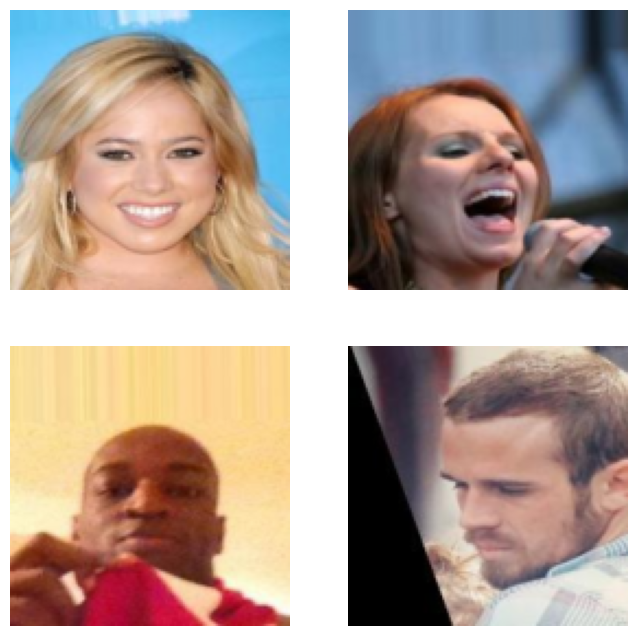

In [29]:
## Visualize some images from the dataset
import matplotlib.pyplot as plt
import numpy as np

for images, labels in train_loader:
    # Plot a few images to verify the transformations
    plt.figure(figsize=(8,8))
    for i in range(4):
        plt.subplot(2, 2, i+1)
        # Print shape of the image tensor
        # print(images[i].shape)
        # Plot the RGB image
        plt.imshow(np.transpose(images[i].numpy(), (1, 2, 0)))
        # Min and max values in image tensor
        # print(torch.min(images[i]), torch.max(images[i]))
        # plt.title(f'Attributes: {labels[i].numpy()}')
        plt.axis('off')
    plt.show()
    break 

In [10]:
## Create a sampling layer for the VAE

class SamplingLayer(nn.Module):
    def __init__(self):
        super(SamplingLayer, self).__init__()

    def forward(self, mu, log_var):
        """Reparameterization trick to get a sample from N(mu, var) when 
           actually randomly sampling from N(0,I).
        
        Args:
            mu: Mean of the latent space Gaussian distribution [batch_size, latent_dim]
            log_var: Log-variance vector of the latent space Gaussian distribution [batch_size, latent_dim]
        """
        # Note: For sampling we need the standard deviation, which is the square root of the variance.
        #       Hence we multiply by 0.5 and then take the exponential to get the standard deviation.
        std = torch.exp(0.5 * log_var)  # [batch_size, latent_dim]
        eps = torch.randn_like(std)     # [batch_size, latent_dim]
        return mu + eps * std

In [11]:
# Define the encoder of the VAE
class Encoder(nn.Module):
    def __init__(self, latent_dim):
        super(Encoder, self).__init__()
        self.latent_dim = latent_dim
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),  # 128x128 -> 64x64
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1), # 64x64 -> 32x32
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),# 32x32 -> 16x16
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),# 16x16 -> 8x8
            nn.BatchNorm2d(256),
            nn.LeakyReLU(),
            nn.Flatten()
        )
        self.fc_mu = nn.Linear(256*8*8, latent_dim)
        self.fc_log_var = nn.Linear(256*8*8, latent_dim)
        self.sampling = SamplingLayer()

    def forward(self, x):
        x = self.conv_layers(x)
        mu = self.fc_mu(x)
        log_var = self.fc_log_var(x)
        z = self.sampling(mu, log_var)
        return z, mu, log_var

In [12]:
## Define the decoder of the VAE
class Decoder(nn.Module):
    def __init__(self, latent_dim):
        super(Decoder, self).__init__()
        self.fc = nn.Linear(latent_dim, 256*8*8)
        self.deconv_layers = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1), # 8x8 -> 16x16
            nn.BatchNorm2d(128),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),  # 16x16 -> 32x32
            nn.BatchNorm2d(64),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),   # 32x32 -> 64x64
            nn.BatchNorm2d(32),
            nn.LeakyReLU(),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),    # 64x64 -> 128x128
            nn.Sigmoid()  # Output pixel values between 0 and 1
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(-1, 256, 8, 8)
        x = self.deconv_layers(x)
        return x

In [13]:
## Define the VAE model
class VAE(nn.Module):
    def __init__(self, latent_dim):
        super(VAE, self).__init__()
        self.encoder = Encoder(latent_dim)
        self.decoder = Decoder(latent_dim)

    def forward(self, x):
        z, mu, log_var = self.encoder(x)
        reconstructed_x = self.decoder(z)
        return reconstructed_x, mu, log_var

### Training the VAE on the celebA dataset

In [26]:
from torch import optim
import torch.nn.functional as F
from tqdm.auto import tqdm
import wandb
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_DIR = "./checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

## Params: 
num_epochs = 10
beta = 1000  # Weight for Reconstruction vs KL divergence
latent_dim = 128
learning_rate = 5e-4

CHECKPOINT_NAME = f"vae_ld_{latent_dim}_beta_{beta}_ep_{num_epochs}.pt"

# Start a new wandb run to track this script.
run = wandb.init(
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="mechtrics7-task-proxemics",
    # Set the wandb project where this run will be logged.
    project="modeling_generation",
    # Run name for this experiment
    name=f"vae_ld_{latent_dim}_beta_{beta}_ep_{num_epochs}",
    # Track hyperparameters and run metadata.
    config={
        "num_epochs": num_epochs,
        "beta": beta,
        "latent_dim": latent_dim,
        "learning_rate": learning_rate
    }
)

# Initialize the VAE, optimizer, and loss function

vae = VAE(latent_dim).to(device)
optimizer = optim.Adam(vae.parameters(), lr=learning_rate)

# Define the loss function
# 1. Reconstruction loss (`MSELoss`)
reconstruction_loss_fn = nn.MSELoss(reduction='mean')

# 2. KL Divergence loss (Mean over the batch)
def kl_divergence(mu, logvar) -> torch.Tensor:
    """Compute the KL divergence between the learned latent distribution and the prior N(0,I).

    Args:
        mu: Mean of the latent space Gaussian distribution [batch_size, latent_dim]
        logvar: Log-variance vector of the latent space Gaussian distribution [batch_size, latent_dim]

    Returns:
        KL divergence averaged over the batch
    """
    # Sum across the dimensions
    sample_losses = 0.5 * torch.sum(logvar.exp() + mu.pow(2) - 1 - logvar, dim=1)
    # Average over the batch
    return torch.mean(sample_losses)

vae.train()

for epoch in range(num_epochs):
    train_loss = 0
    progress = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}', unit='batch')
    for batch_idx, (images, _) in enumerate(progress):
        images = images.to(device)
        batch_size = images.size(0)
        optimizer.zero_grad()
        reconstructed_batch, mu, log_var = vae(images)
        recon_loss = reconstruction_loss_fn(reconstructed_batch, images)
        kl_loss = kl_divergence(mu, log_var)
        loss = beta * recon_loss + kl_loss
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
        progress.set_postfix(loss=f'{train_loss / (batch_idx + 1):.4f}')
        run.log({"batch_loss": loss.item(), "recon_loss": recon_loss.item(), "kl_loss": kl_loss.item()})
    print(f'Epoch {epoch+1}, Loss: {train_loss / len(train_loader)}')
    run.log({"epoch": epoch+1, "loss": train_loss / len(train_loader),
               "recon_loss": recon_loss.item(), "kl_loss": kl_loss.item()})

# Save the trained model checkpoint locally
torch.save(vae.state_dict(), os.path.join(CHECKPOINT_DIR, CHECKPOINT_NAME))

# Save the trained model checkpoint to the W&B run as an artifact
artifact = wandb.Artifact("vae_checkpoint", type="model")
artifact.add_file(os.path.join(CHECKPOINT_DIR, CHECKPOINT_NAME))
run.log_artifact(artifact)

# Finish the W&B run
run.finish()

Epoch 1/10: 100%|██████████| 1272/1272 [00:55<00:00, 22.76batch/s, loss=48.7291]


Epoch 1, Loss: 48.729137348678876


Epoch 2/10: 100%|██████████| 1272/1272 [00:55<00:00, 22.78batch/s, loss=40.0456]


Epoch 2, Loss: 40.04557331852943


Epoch 3/10: 100%|██████████| 1272/1272 [00:56<00:00, 22.54batch/s, loss=39.1908]


Epoch 3, Loss: 39.190848656420435


... (11 outputs left out)

Epoch 9, Loss: 38.05002014891906


Epoch 10/10: 100%|██████████| 1272/1272 [00:59<00:00, 21.43batch/s, loss=37.9708]


Epoch 10, Loss: 37.97075851008577


batch_loss,█▅▂▃▂▂▂▂▂▂▃▃▂▂▁▃▂▂▁▁▁▂▁▃▂▁▁▁▁▂▂▂▁▁▃▂▂▁▂▂
epoch,▁▂▃▃▄▅▆▆▇█
kl_loss,▁▇▅▆▇█▇▇█▆█▇██▅▇▆▆█▆▇▇█▇▇█▇█▇▇█▇▇▇▇██▇█▇
loss,█▂▂▁▁▁▁▁▁▁
recon_loss,█▆▅▄▃▄▃▃▄▃▂▃▂▂▂▃▂▂▃▃▂▂▃▂▂▃▂▂▁▁▁▂▂▂▂▁▂▂▁▁
batch_loss,36.91656
epoch,10
kl_loss,11.0689
loss,37.97076
recon_loss,0.02585


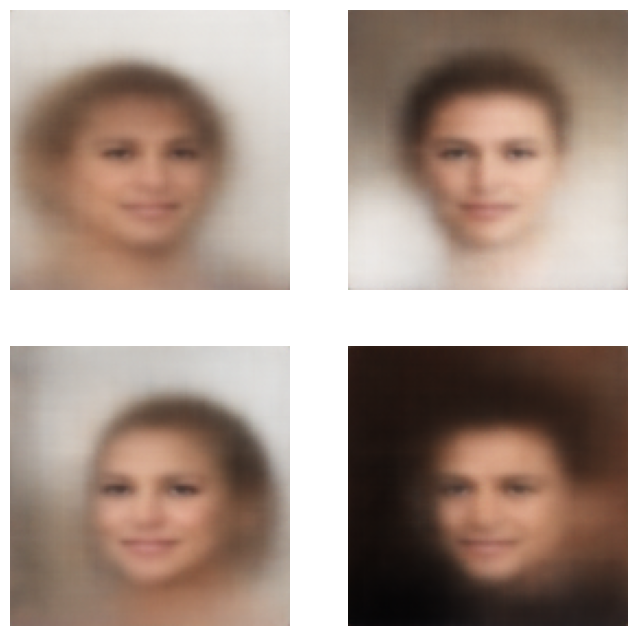

In [27]:
## Sample the latent space and generate new images
vae.eval()

with torch.no_grad():
    # Sample random latent vectors
    z = torch.randn(4, latent_dim).to(device)
    # Generate images from the sampled latent vectors
    generated_images = vae.decoder(z)
    
    # Plot the generated images
    fig, axes = plt.subplots(2, 2, figsize=(8, 8))
    for i in range(4):
        axes[i//2, i%2].imshow(np.transpose(generated_images[i].cpu().numpy(), (1, 2, 0)))
        axes[i//2, i%2].axis('off')
    plt.show()

### Latent Space Interpolation

- Select two random images from the dataset and encode them into the latent space.
- Interpolate between their latent vectors and decode the interpolated vectors to visualize the transition.

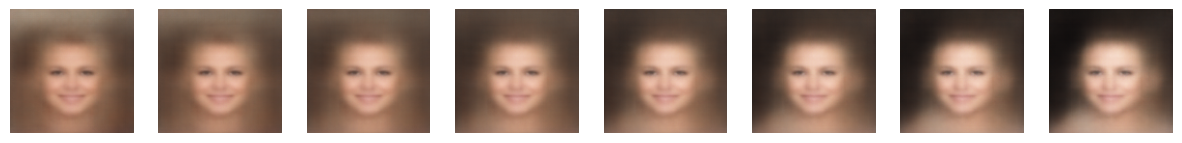

In [28]:
## Latent Space Interpolation

import matplotlib.pyplot as plt
import torch

vae.eval()  # Set the VAE to evaluation mode

# Select two random images from the dataset
idx = torch.randint(0, len(train_loader.dataset), (2,))
images = torch.stack([train_loader.dataset[i][0] for i in idx]).to(device)

# Encode the images into the latent space
with torch.no_grad():
    z, mu, log_var = vae.encoder(images)

# Interpolate between the latent vectors
num_interpolations = 8
interpolated_images = []
for alpha in torch.linspace(0, 1, num_interpolations):
    z_interp = (1 - alpha) * z[0] + alpha * z[1]
    with torch.no_grad():
        reconstructed = vae.decoder(z_interp.unsqueeze(0))
    interpolated_images.append(reconstructed.squeeze(0))

# Plot the interpolated images
fig, axes = plt.subplots(1, num_interpolations, figsize=(15, 3))
for i, img in enumerate(interpolated_images):
    axes[i].imshow(img.permute(1, 2, 0).cpu().numpy())
    axes[i].axis('off')
plt.show()